# Miniproyecto 3: Clasificación de animales

## Entrega 1

La clasificación es una de las principales tareas en machine learning. En particular, la clasificación de imágenes consiste en asignar una etiqueta a una imagen a partir de un conjunto finito de clases posibles. En el enfoque clásico de machine learning, este proceso se basa en la extracción de descriptores o características, que son vectores que representan información relevante de una imagen y permiten categorizarla, y posteriormente en su clasificación mediante modelos clasificadores.

Aunque el problema parece sencillo, en la práctica presenta varios desafíos. Las clases pueden tener una gran variabilidad tanto entre sí como dentro de cada una, lo que dificulta la clasificación automática. En visión por computador, la precisión de los modelos depende tanto de la calidad de los descriptores extraídos como del rendimiento de los clasificadores utilizados para separar las categorías.

En este Mini-proyecto, exploraremos diferentes tipos de descriptores visuales, centrándonos en tres principales:

1. Descriptores basados en Color (como histogramas de color, que capturan la distribución de colores en la imagen).

2. Descriptores de Textura (como patrones de intensidad que reflejan la rugosidad o suavidad de una superficie).

3. Descriptores de Forma (que representan contornos y estructuras geométricas de los objetos en la imagen).

Estos descriptores transforman la información visual en representaciones numéricas que los algoritmos pueden procesar para la clasificación. Una vez obtenidos, utilizaremos modelos clasificadores para aprender fronteras de decisión y clasificar nuevas imágenes.

### Base de Datos y Asignación de Clases
Trabajaremos con la base de datos [iNaturalist](https://github.com/visipedia/inat_comp.git), un conjunto de imágenes de seres vivos utilizado en tareas de clasificación. Para este proyecto, nos enfocaremos en un subconjunto de 23 especies de mamíferos con el mayor número de imágenes dentro de las versiones del dataset (2017, 2018 y 2021). Las clases estarán identificadas por sus nombres científicos.

Dado que el dataset sigue siendo grande, y para garantizar una experiencia equitativa y desafiante para cada grupo, cada equipo trabajará con cinco especies de mamíferos. Para mantener un número equilibrado de imágenes por grupo, hemos dividido las 23 especies en cinco grupos, cada uno con diferentes cantidades de imágenes. De manera aleatoria todos los equipos obtendrán una especie de cada grupo, asegurando así que todos trabajen con un conjunto similar en tamaño.

### Consideraciones Adicionales
Es importante notar que las imágenes del dataset no solo incluyen avistamientos directos de los animales, sino también huellas, excrementos y otros rastros. Esto puede hacer que algunas imágenes sean difíciles de clasificar, incluso para algoritmos avanzados.


### Parte 1: Exploración de la base de datos

#### Parte 1.1: Entrega de las clases
En las siguientes celdas, encontrarán las clases asignadas a su grupo. Para verlas, deben asignar a la variable `grupo` el número correspondiente a su equipo dentro del Bloque Neón.

In [1]:
# importar librerías importantes
import os
import random
import numpy as np
from glob import glob
from matplotlib import pyplot as plt

import cv2

In [2]:
group = 2 # Cambiar por el número de grupo

In [3]:
def determine_classes(group: int) -> list:
    """Función que determina las clases a utilizar en el proyecto.

    Args:
        group (int): Número de grupo.

    Returns:
        list: Lista con los nombres de las clases a utilizar.
    """
    # Se fija la semilla para reproducibilidad
    random.seed(group)
    
    # Se obtienen las categorías y la cantidad de imágenes por categoría
    stats = [('Canis latrans', 1286), ('Castor canadensis', 854), ('Dasypus novemcinctus', 515), ('Didelphis virginiana', 713), 
             ('Lepus californicus', 515), ('Lynx rufus', 854), ('Megaptera novaeangliae', 515), ('Mephitis mephitis', 515), 
             ('Odocoileus hemionus', 1286), ('Odocoileus virginianus', 1795), ('Otospermophilus beecheyi', 854), 
             ('Otospermophilus variegatus', 515), ('Phoca vitulina', 713), ('Procyon lotor', 1286), ('Sciurus carolinensis', 1795), 
             ('Sciurus niger', 1795), ('Sylvilagus audubonii', 515), ('Sylvilagus floridanus', 854), ('Tamias striatus', 854), 
             ('Tamiasciurus hudsonicus', 713), ('Urocyon cinereoargenteus', 515), ('Ursus americanus', 713), ('Vulpes vulpes', 854)]
    
    # Se agrupan las categorías por cantidad de imágenes
    clusters = {}
    for category, num_images in stats:
        if num_images in clusters:
            clusters[num_images].append(category)
        else:
            clusters[num_images] = [category]
    
    # Se selecciona una categoría aleatoria de cada cluster
    categories = []
    for cluster_categories in clusters.values():
        categories += [random.choice(cluster_categories)]
    return categories

assert group is not None, "Por favor, asigna un número de grupo a la variable 'group'."
assert group > 0, "El número de grupo debe ser mayor que 0."
assert group <= 28, "El número de grupo debe ser menor o igual que 28."

categories = determine_classes(group)
print(f"Las classes que usarán en este Mini-proyecto serán:\n{", ".join(categories)}.")

Las classes que usarán en este Mini-proyecto serán:
Canis latrans, Castor canadensis, Dasypus novemcinctus, Tamiasciurus hudsonicus, Odocoileus virginianus.


Al igual que en los mini-proyectos anteriores, es fundamental comenzar analizando la base de datos con la que trabajaremos. Primero, vamos a crear un identificador único (ID) para cada una de las clases de mamíferos. Para ello, generaremos un diccionario en el que las claves sean los nombres de los mamíferos ordenados alfabéticamente, y los valores sean los IDs correspondientes. Recuerden que el ID debe asignarse en el mismo orden alfabético, es decir, el primer animal en la lista debe tener el ID 0.

A continuación, deberán implementar una función que genere dos listas:

1. Una lista con las rutas de las imágenes correspondientes al split.

2. Una lista con las etiquetas, que son los IDs de los animales asignados, utilizando el diccionario que mapea de nombre a ID.

**Nota:** Asegúrense de que las listas solo contengan las clases que se les han asignado a su grupo y no todas las categorías disponibles en el dataset.

In [4]:
dict_labels = {} # Cambiar por un diccionario con las etiquetas de las clases

# YOUR CODE HERE
dict_labels.update({category: label for label, category in enumerate(sorted(categories))})

def get_data(subset: str) -> tuple[list, list]:
  """Función que obtiene las rutas de las imágenes y sus etiquetas.

  Args:
      subset (str): Nombre del subconjunto de datos a utilizar.

  Returns:
      tuple[list, list]: Rutas de las imágenes y sus etiquetas.
  """
  paths = [] # Cambiar por una lista con las rutas de las imágenes
  labels = [] # Cambiar por una lista con las etiquetas de las imágenes
  
  # YOUR CODE HERE
  if subset not in ("train", "valid", "test"):
    raise ValueError("subset debe ser 'train', 'valid' o 'test'.")

  data_dir = os.path.join(os.path.expanduser("~"), "Downloads", "dataset")
  for category in dict_labels:
    category_paths = sorted(glob(os.path.join(data_dir, subset, category, "*")))
    category_paths = [path for path in category_paths if os.path.isfile(path)]
    paths.extend(category_paths)
    labels.extend([dict_labels[category]] * len(category_paths))

  return paths, labels

train_paths, train_labels = get_data("train")
valid_paths, valid_labels = get_data("valid")
test_paths, test_labels = get_data("test")

In [5]:
assert len(train_paths) > 0, "No se ha cargado ningún dato de entrenamiento"
assert len(train_paths) == 5163, "El número de datos de entrenamiento no es correcto"
assert len(valid_paths) > 0, "No se ha cargado ningún dato de validación"
assert len(valid_paths) == 1723, "El número de datos de validación no es correcto"
assert len(test_paths) > 0, "No se ha cargado ningún dato de test"
assert len(test_paths) == 1724, "El número de datos de test no es correcto"

assert type(train_paths[0]) == str, "Los datos de entrenamiento no tienen la forma correcta"
assert type(valid_paths[0]) == str, "Los datos de validación no tienen la forma correcta"
assert type(test_paths[0]) == str, "Los datos de test no tienen la forma correcta"

assert type(train_labels[0]) == int, "Las etiquetas de entrenamiento no tienen la forma correcta"
assert type(valid_labels[0]) == int, "Las etiquetas de validación no tienen la forma correcta"
assert type(test_labels[0]) == int, "Las etiquetas de test no tienen la forma correcta"

assert len(dict_labels) == len(categories), "El diccionario de labels no tiene la longitud correcta"

categories_sorted = sorted(categories)
assert list(dict_labels.keys()) == categories_sorted, "Las llaves del diccionario de labels no son correctas"
assert list(dict_labels.values()) == list(range(len(categories))), "Los valores del diccionario de labels no son correctos"

assert min([dict_labels[train_paths[i].split(os.sep)[-2]] == train_labels[i] for i in range(len(train_paths))]), "Las etiquetas de entrenamiento no coinciden"
assert min([dict_labels[valid_paths[i].split(os.sep)[-2]] == valid_labels[i] for i in range(len(valid_paths))]), "Las etiquetas de validación no coinciden"
assert min([dict_labels[test_paths[i].split(os.sep)[-2]] == test_labels[i] for i in range(len(test_paths))]), "Las etiquetas de test no coinciden"

En el informe del miniproyecto, en la sección dedicada al análisis del Dataset, debes incluir las siguientes estadísticas y análisis:

1. Cantidad de imágenes por clase:

    Debes reportar cuántas imágenes hay de cada clase en cada uno de los conjuntos (train, valid y test). Presenta estos datos en una tabla o gráfico para facilitar la interpretación.

2. Distribución de datos en los folds:

    Analiza y comenta sobre la distribución de los datos en los diferentes conjuntos (train, valid y test). ¿Están equilibradas las clases o alguna tiene más ejemplos que las demás?

3. Ejemplos visuales:

    Incluye algunas imágenes de ejemplo para cada clase, extraídas de los distintos conjuntos (train, valid y test). Muestra al menos una imagen de cada clase para que quede claro cómo lucen visualmente las diferentes categorías.

4. Otras estadísticas relevantes:

    Además, pueden presentar cualquiera otra estadística que crean relevante. Ejemplo: ¿Todas las imágenes están a color, es decir, hay algunas imágenes en escala de grises?

Clase                                  Train    Valid     Test
Canis latrans                           1286      429      429
Castor canadensis                        854      285      285
Dasypus novemcinctus                     515      172      173
Odocoileus virginianus                  1795      599      599
Tamiasciurus hudsonicus                  713      238      238


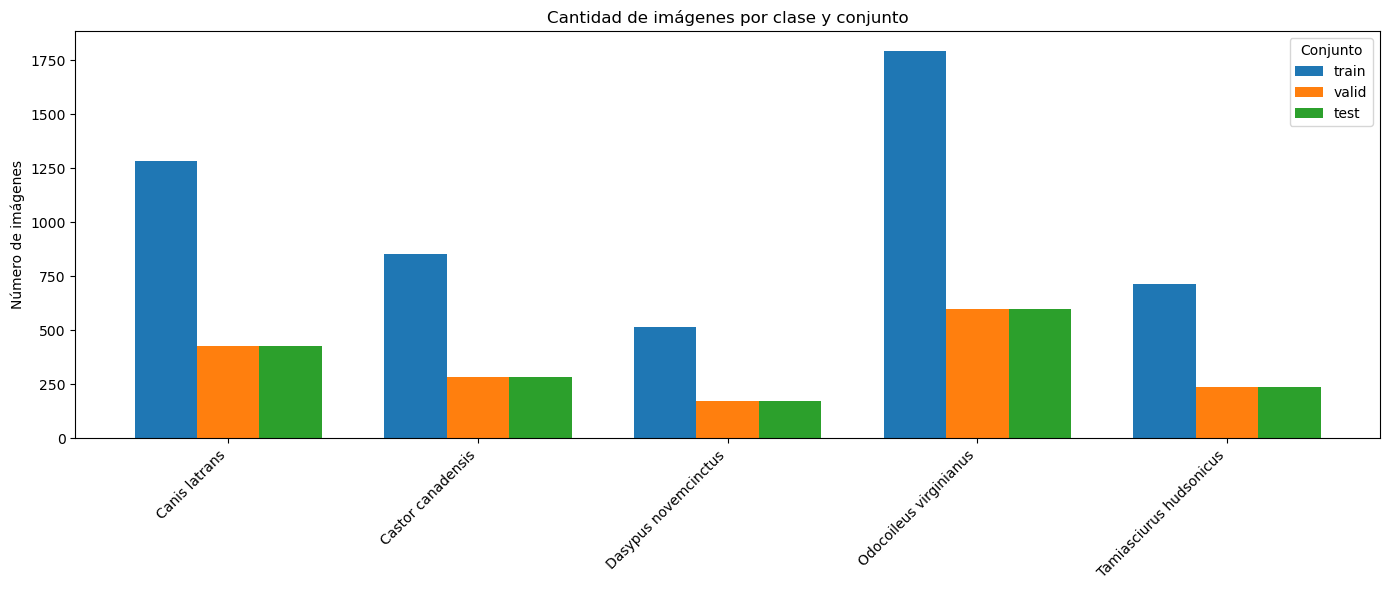

train: entre 515 y 1795 imágenes por clase (diferencia: 1280).
valid: entre 172 y 599 imágenes por clase (diferencia: 427).
test: entre 173 y 599 imágenes por clase (diferencia: 426).


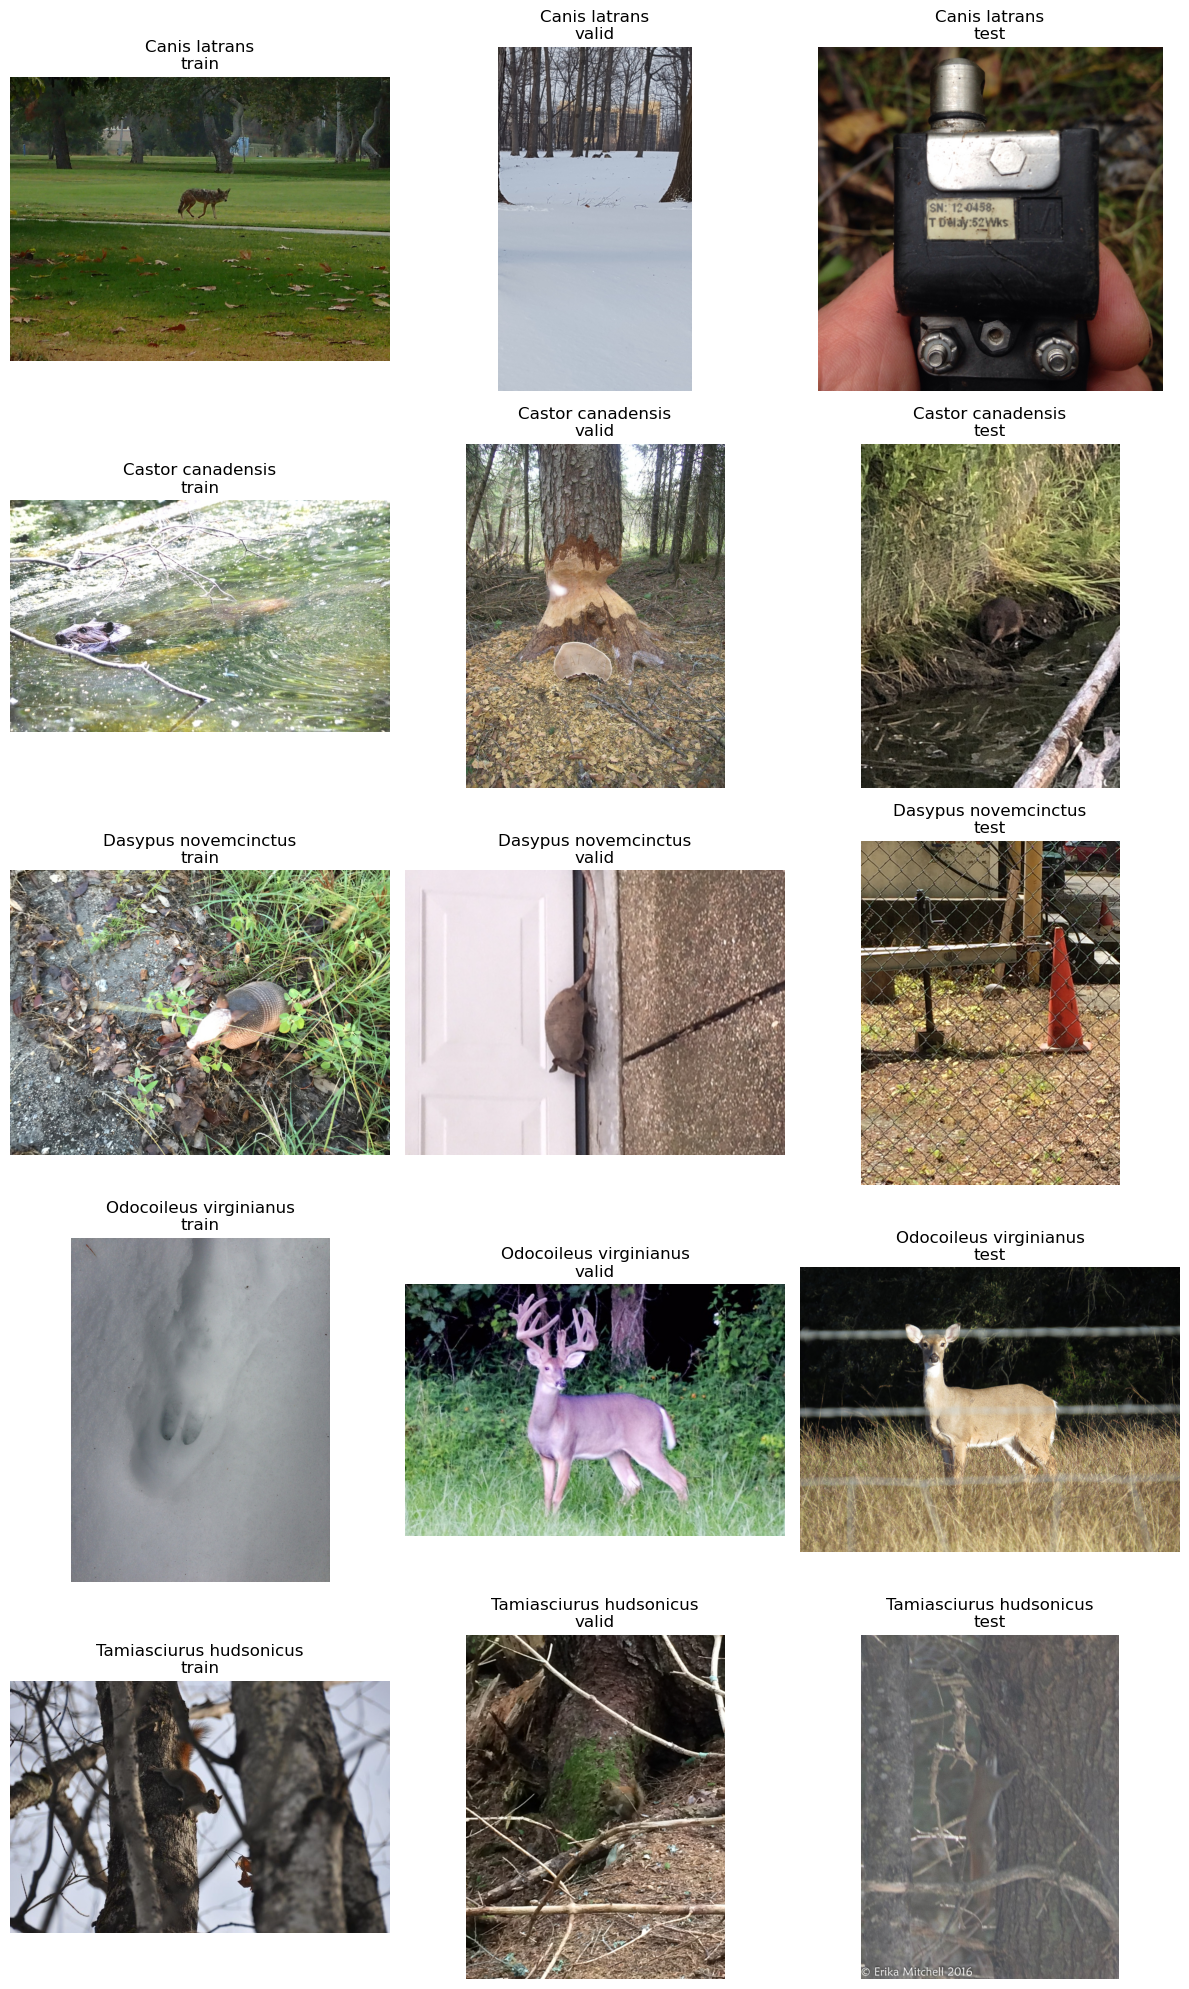

Imágenes guardadas en escala de grises: 89
Imágenes guardadas a color: 8521
Imágenes que no se pudieron abrir: 0


In [6]:
splits = {
    "train": (train_paths, train_labels),
    "valid": (valid_paths, valid_labels),
    "test": (test_paths, test_labels),
}

counts = {}
for category, label in dict_labels.items():
    counts[category] = {
        subset: sum(current_label == label for current_label in labels)
        for subset, (_, labels) in splits.items()
    }

print(f"{'Clase':35} {'Train':>8} {'Valid':>8} {'Test':>8}")
for category, split_counts in counts.items():
    print(
        f"{category:35} {split_counts['train']:8d} "
        f"{split_counts['valid']:8d} {split_counts['test']:8d}"
    )

x = np.arange(len(dict_labels))
bar_width = 0.25
fig, ax = plt.subplots(figsize=(14, 6))
for offset, subset in enumerate(splits):
    values = [counts[category][subset] for category in dict_labels]
    ax.bar(x + (offset - 1) * bar_width, values, bar_width, label=subset)
ax.set_xticks(x)
ax.set_xticklabels(dict_labels.keys(), rotation=45, ha="right")
ax.set_ylabel("Número de imágenes")
ax.set_title("Cantidad de imágenes por clase y conjunto")
ax.legend(title="Conjunto")
fig.tight_layout()
plt.show()

for subset in splits:
    values = [counts[category][subset] for category in dict_labels]
    print(
        f"{subset}: entre {min(values)} y {max(values)} imágenes por clase "
        f"(diferencia: {max(values) - min(values)})."
    )

fig, axes = plt.subplots(len(dict_labels), len(splits), figsize=(12, 4 * len(dict_labels)))
for row, (category, label) in enumerate(dict_labels.items()):
    for column, (subset, (paths, labels)) in enumerate(splits.items()):
        ax = axes[row, column]
        sample_path = next(
            (path for path, current_label in zip(paths, labels) if current_label == label),
            None,
        )
        if sample_path is None:
            ax.text(0.5, 0.5, "Sin imágenes", ha="center", va="center")
        else:
            image = cv2.imread(sample_path)
            if image is not None:
                ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            else:
                ax.text(0.5, 0.5, "No se pudo abrir", ha="center", va="center")
        ax.set_title(f"{category}\n{subset}")
        ax.axis("off")
fig.tight_layout()
plt.show()

gray_images = 0
color_images = 0
unreadable_images = 0
for paths, _ in splits.values():
    for path in paths:
        image = cv2.imread(path, cv2.IMREAD_UNCHANGED)
        if image is None:
            unreadable_images += 1
        elif image.ndim == 2 or (image.ndim == 3 and image.shape[2] == 1):
            gray_images += 1
        else:
            color_images += 1

print(f"Imágenes guardadas en escala de grises: {gray_images}")
print(f"Imágenes guardadas a color: {color_images}")
print(f"Imágenes que no se pudieron abrir: {unreadable_images}")

### Parte 2: Preprocesamiento de las imágenes

#### Parte 2.1: Preprocesamientos básicos
Durante todo el Mini-proyecto, realizaremos algunos preprocesamientos básicos para asegurarnos de que todas las imágenes estén en un formato consistente y aprovechar información relevante. Principalmente, nos centraremos en redimensionar las imágenes y realizar conversiones en los espacios de color. Por lo tanto, deberán crear una función que, dada una imagen, una tupla con las dimensiones de redimensionado y un espacio de color, aplique estas transformaciones a la imagen. En caso de que los parámetros de entrada `img_size` y/o `color_space` sean None debe no aplicar lo(s) procesamientos correspondientes.

**Nota:** Para facilitar la interacción con los asserts y mejorar la eficiencia del código, utilicen exclusivamente funciones de OpenCV-Python. Además, recuerden que la función `cv2.imread` lee las imágenes en formato BGR en lugar de RGB, por lo que para obtener la representación RGB correcta deberán realizar la conversión correspondiente.

In [7]:
def processing(Im: np.ndarray, img_size: tuple[int] | None = None, color_space: str | None = None) -> np.ndarray:
    """Función que preprocesa una lista de imágenes.

    Args:
        Im_list (list[np.ndarray]): Lista con las imágenes a preprocesar.
        img_size (tuple[int] | None): Tamaño de la imagen.
        color_space (str | None): Espacio de color a utilizar. Puede ser "rgb", "gray", "hsv" o "lab".

    Returns:
        list[np.ndarray]: Lista con las imágenes preprocesadas.
    """
    if img_size is not None:
        Im = cv2.resize(Im, img_size)

    conversions = {
        "rgb": cv2.COLOR_BGR2RGB,
        "gray": cv2.COLOR_BGR2GRAY,
        "hsv": cv2.COLOR_BGR2HSV,
        "lab": cv2.COLOR_BGR2LAB,
    }
    if color_space is not None:
        if color_space not in conversions:
            raise ValueError("color_space debe ser 'rgb', 'gray', 'hsv' o 'lab'.")
        Im = cv2.cvtColor(Im, conversions[color_space])

    return Im

In [8]:
Im_list = [cv2.imread(path) for path in train_paths[:5]]
img_size = (224, 224)
color_space = "rgb"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]

assert len(Im_proc) == len(Im_list), "El número de imágenes preprocesadas no es correcto"
assert type(Im_proc) == list, "Las imágenes preprocesadas no están en una lista"
assert type(Im_proc[0]) == np.ndarray, "Las imágenes preprocesadas no son arreglos de numpy"
assert np.array(Im_proc).shape[1:] == (224, 224, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2RGB), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

color_space = "gray"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (224, 224), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2GRAY), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

color_space = "hsv"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (224, 224, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2HSV), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

color_space = "lab"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (224, 224, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2LAB), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

Im_proc = [processing(Im, (256, 256)) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (256, 256, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.resize(Im_list[0], (256, 256)), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

Im_proc = [processing(Im, None, "lab") for Im in Im_list]
assert np.array_equal(cv2.cvtColor(Im_list[0], cv2.COLOR_BGR2LAB), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

#### Parte 2.2: Data Augmentation

Data Augmentation hace referencia a técnicas que permiten el aumento de datos de manera sintetica para poder mejorar los resultados de un modelo. La idea principal de estas técnicas realizar transformaciones geométricas o de intensidad sobre las imágenes de tal manera que tengamos imágenes similares pero con ligeras diferencias. En este caso vamos a crear una función que realice 3 transformaciones. La primera será un tranformación geométrica que refleja la imagen respecto al eje y. La segunda y tercera transformación será una que ajuste de forma aleatoria el contraste y el brillo de una imagen, para estas dos puede utilizar la función [convertScaleAbs](https://docs.opencv.org/4.x/d2/de8/group__core__array.html#ga3460e9c9f37b563ab9dd550c4d8c4e7d) (en este [enlace](https://opencv.courses/blog/image-enhancement-with-opencv/) hay un pequeño tutorial), en esta función alpha hace referencia al contraste y beta al brillo.

Para el correcto funcionamiento de la función realizaremos el ajuste de contraste de manera aleatoria siguiendo una función de probabilidad uniforme con valores que entran por parámetro. Así mismo, para el ajuste de contraste haremos el mismo procedimiento.

**Nota:** En este caso tenemos 3 transformaciones. Sin embargo, tendremos 4 casos debido a que si realizamos las dos operaciones "brightness and contrast" tenemos que realizarlas al mismo tiempo.

In [9]:
def data_augmentation(Im: np.ndarray, transformations: list[str], alpha_factor: tuple[float] | None = None, beta_factor: tuple[int] | None = None) -> np.ndarray:
    """Función que realiza data augmentation a una imagen.

    Args:
        Im (np.ndarray): Imagen a transformar.
        transformations (list[str]): Lista de transformaciones a aplicar. Los valores posibles son "flip", "brightness", "contrast" y "brightness and contrast".
        alpha_factor (tuple[float] | None): Factor de ajuste de brillo. Si es None, no se aplica.
        beta_factor (tuple[int] | None): Factor de ajuste de contraste. Si es None, no se aplica.

    Returns:
        np.ndarray: Imagen transformada.
    """
    valid_transformations = {"flip", "brightness", "contrast", "brightness and contrast"}
    if any(transformation not in valid_transformations for transformation in transformations):
        raise ValueError("Transformación no válida.")

    if "flip" in transformations:
        Im = cv2.flip(Im, 1)

    apply_contrast = "contrast" in transformations or "brightness and contrast" in transformations
    apply_brightness = "brightness" in transformations or "brightness and contrast" in transformations

    if apply_contrast or apply_brightness:
        alpha = random.uniform(*alpha_factor) if apply_contrast and alpha_factor is not None else 1
        beta = random.uniform(*beta_factor) if apply_brightness and beta_factor is not None else 0
        Im = cv2.convertScaleAbs(Im, alpha=alpha, beta=beta)

    return Im

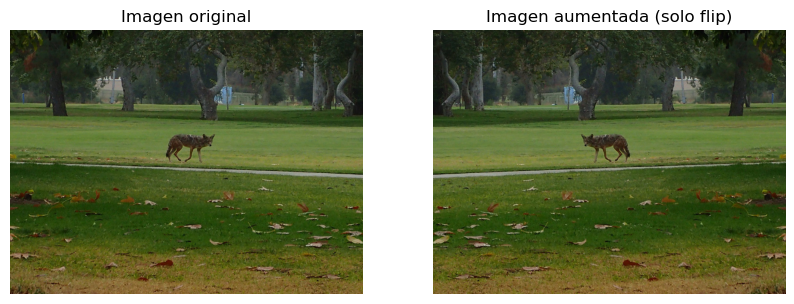

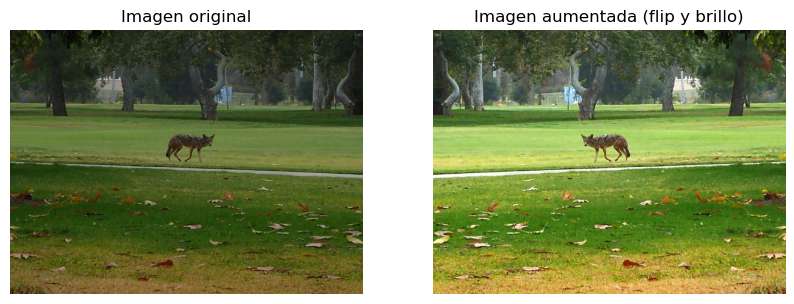

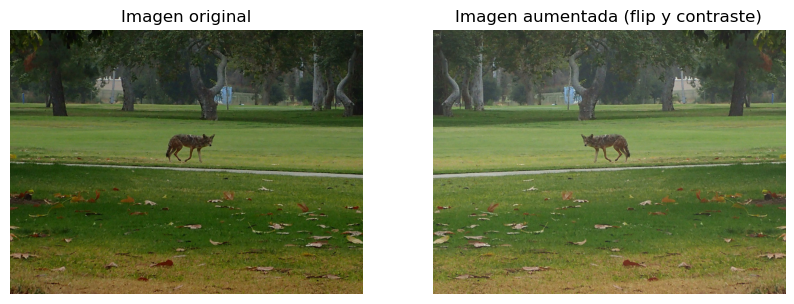

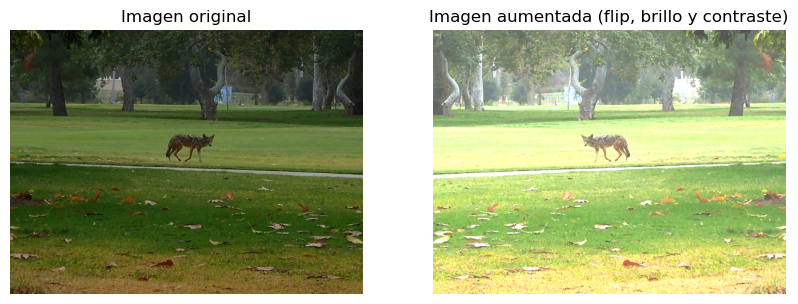

In [10]:
Im = Im_list[0]
transformations = ["flip"]
Im_aug = data_augmentation(Im, transformations)
Im_aug = cv2.cvtColor(Im_aug, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv2.cvtColor(Im, cv2.COLOR_BGR2RGB))
ax[0].set_title("Imagen original")
ax[0].axis("off")
ax[1].imshow(Im_aug)
ax[1].set_title("Imagen aumentada (solo flip)")
ax[1].axis("off")
plt.show()

assert Im.shape == Im_aug.shape, "La imagen aumentada no tiene el mismo tamaño que la original"
assert np.array_equal(cv2.cvtColor(Im[:, ::-1], cv2.COLOR_BGR2RGB), Im_aug), "La imagen aumentada no es igual a la original"

transformations = ["flip", "contrast"]
random.seed(1) # Para reproducibilidad
Im_aug = data_augmentation(Im, transformations, (1.5, 2.5))
random.seed(1) # Para reproducibilidad
first_way = cv2.convertScaleAbs(Im[:, ::-1], alpha=random.uniform(1.5, 2.5), beta=0)
assert Im_aug.shape == Im.shape, "La imagen aumentada no tiene el mismo tamaño que la original"
assert np.array_equal(first_way, Im_aug), "La imagen aumentada no es igual a la original"

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv2.cvtColor(Im, cv2.COLOR_BGR2RGB))
ax[0].set_title("Imagen original")
ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(Im_aug, cv2.COLOR_BGR2RGB))
ax[1].set_title("Imagen aumentada (flip y brillo)")
ax[1].axis("off")
plt.show()

transformations = ["flip", "brightness"]
random.seed(1) # Para reproducibilidad
Im_aug = data_augmentation(Im, transformations, None, (20, 80))
random.seed(1) # Para reproducibilidad
first_way = cv2.convertScaleAbs(Im[:, ::-1], alpha=1, beta=random.uniform(20, 80))
assert Im_aug.shape == Im.shape, "La imagen aumentada no tiene el mismo tamaño que la original"
assert np.array_equal(first_way, Im_aug), "La imagen aumentada no es igual a la original"

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv2.cvtColor(Im, cv2.COLOR_BGR2RGB))
ax[0].set_title("Imagen original")
ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(Im_aug, cv2.COLOR_BGR2RGB))
ax[1].set_title("Imagen aumentada (flip y contraste)")
ax[1].axis("off")
plt.show()

transformations = ["flip", "brightness and contrast"]
random.seed(1) # Para reproducibilidad
Im_aug = data_augmentation(Im, transformations, (1.5, 2.5), (20, 80))
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv2.cvtColor(Im, cv2.COLOR_BGR2RGB))
ax[0].set_title("Imagen original")
ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(Im_aug, cv2.COLOR_BGR2RGB))
ax[1].set_title("Imagen aumentada (flip, brillo y contraste)")
ax[1].axis("off")
plt.show()

random.seed(1) # Para reproducibilidad
alpha = random.uniform(1.5, 2.5)
beta = random.uniform(20, 80)
first_way = cv2.convertScaleAbs(Im[:, ::-1], alpha=alpha, beta=beta)
assert np.array_equal(first_way, Im_aug), "La imagen aumentada no es igual a la original"

## Entregables
Los entregables para esta primera entrega son los siguientes:

- Jupyter notebook (.ipynb): El notebook debe estar completamente resuelto. Recuerden que la nota depende del correcto funcionamiento de su código.

- Secciones requeridas del artículo (.pdf): Un documento en PDF que incluya las secciones solicitadas del artículo. La extensión máxima de esta entrega es de 2 páginas. Deben seguir el formato proporcionado en el siguiente [enlace](https://github.com/cvpr-org/author-kit). Si tienen dudas sobre cómo utilizar el formato, pueden consultar al Asistente Graduado.

- Informe (.pdf): Un informe que describa lo realizado en esta entrega, incluyendo visualizaciones, análisis y otros aspectos relevantes para demostrar el desarrollo de la entrega de miniproyecto. Este informe no requiere una estructura específica, sino que debe servir para confirmar que han desarrollado correctamente la entrega.

- Archivo de texto (.txt): Un archivo de texto con las secciones de código del Jupyter notebook. Para más información sobre cómo convertir las secciones de código de su Jupyter notebook a un archivo de texto, pueden ver el video disponible en el siguiente [enlace](https://uniandes-edu-co.zoom.us/rec/share/QOxUUIw7Uz9DsnKPyftOXZgM4bx5d7KHMYK-dqvGnkyJ2GfqvT7NU3lhQc0NtNSU.jveWB2H34S4uLIoB).


## Artículo
En esta primera entrega, iremos construyendo el artículo, cuya extensión máxima será de 2 páginas.

### Introducción:
Es fundamental conocer el contexto del problema para plantear correctamente el proyecto. En esta primera entrega del artículo, deben incluir el contexto del problema, la motivación para resolverlo, la definición del problema y justificar su relevancia (poniendo en contexto el problema de la clasificación de animales). Pueden guiarse de las siguientes preguntas:

>- ¿Qué problema se va a trabajar?
>- ¿Por qué es importante trabajar esta problemática?
>- ¿Qué indicadores suelen usarse para realizar esta tarea manualmente?
>- ¿Qué problemas podrían encontrarse en el proceso de clasificación?
>- ¿Qué ejemplos existen de estos problemas?
>- ¿Por qué es necesario utilizar análisis de imágenes para resolver esta tarea?
>- ¿Cuál es el objetivo de clasificar imágenes de animales?

### Estado del arte:
Una vez contextualizado el problema, es necesario comprender cómo ha sido abordado anteriormente. En esta sección, deben completar la investigación sobre la problemática de la clasificación de animales. La base de datos sobre la cual estarán trabajando es completamente nueva, por lo que no es necesario incluir metodologías específicas relacionadas con ella. Pueden guiarse de las siguientes preguntas:

>- ¿Cómo se ha estudiado este problema en el pasado?
>- ¿Qué algoritmos se han utilizado?
>- ¿Qué descriptores se han usado para la clasificación?
>- ¿Qué clasificadores se han implementado?
>- ¿Cuáles son las bases de datos existentes y las metodologías de evaluación?
>- ¿Cuántas clases tienen?

### Base de datos:
Ya que cuentan con el contexto y la revisión del estado del arte, es momento de describir la base de datos con la que están trabajando. Al ser una base de datos completamente nueva, es importante realizar una descripción completa, incluyendo la cantidad de datos, distribución y otros elementos importantes. Pueden guiarse de las siguientes preguntas:

>- ¿Qué clases hay en la base de datos?
>- ¿Cómo son las imágenes?
>- ¿Cómo están distribuidas las carpetas de entrenamiento, validación y prueba?
>- ¿Cuántas instancias hay de cada una de las clases?

Si consideran necesario hacer un submuestreo, especifiquen claramente las razones. Además, deben describir cómo realizaron el submuestreo, cuántas imágenes se usaron para los experimentos y las métricas finales.

In [ ]:
import json
from pathlib import Path


def converter(filename: str) -> None:
    notebook_path = Path(filename).with_suffix(".ipynb")
    if not notebook_path.exists():
        notebook_path = Path.cwd() / "Mini-e3.1" / notebook_path.name
    if not notebook_path.exists():
        raise FileNotFoundError(f"No se encontró el notebook: {notebook_path}")

    with notebook_path.open(encoding="utf-8") as notebook_file:
        notebook = json.load(notebook_file)

    code_cells = [
        "".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "code"
    ]
    output_path = notebook_path.with_suffix(".txt")
    output_path.write_text("\n\n".join(code_cells), encoding="utf-8")
    print(f"Archivo generado: {output_path}")


converter("Entrega 1")

ModuleNotFoundError: No module named 'utils'